# Hierarchical Clustering - UPGMA

---
## Learning Objectives

1. Implement a distance-based phylogeny neighbor joining algorithm
1. Understanding of hierarchical clustering
1. Manipulation of arrays and lists in Python


---
## Imports
You will need to install a two new packages to properly render your phylogenetic trees. Using your preferred package manager, install both [`biopython`](https://biopython.org/) and `matplotlib` into your virtual environments.

For example:
```bash
$ micromamba create -n module06 -c bioconda -c conda-forge python numpy matplotlib biopython
```

In [3]:
%pip install numpy matplotlib biopython


[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: pip3.13 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [4]:
from typing import List, Tuple, Dict
from io import StringIO

import matplotlib.pyplot as plt
from Bio import Phylo
import numpy as np

---
## Background

Today we will implement a distance-based phylogenetic tree construction method using the Neighbor-Joining (NJ) algorithm and Smith-Waterman local alignment scores. Unlike UPGMA (Unweighted Pair Group Method using Arithmetic averages), NJ produces unrooted trees and does not assume a constant evolutionary rate across lineages, making it more biologically realistic for analyzing sequence relationships.

We will use HIV-1 reverse transcriptase sequences to construct our phylogenetic tree. The Smith-Waterman algorithm will be used to generate pairwise local alignment scores, which will then be converted into distances for tree construction. This approach is particularly suitable for HIV sequence analysis as it:
1. Handles sequence variations effectively through local alignment
2. Accounts for potential rate heterogeneity across different viral strains
3. Does not assume a molecular clock

The ultimate output will be an unrooted phylogenetic tree representing the evolutionary relationships between the HIV-1 sequences, visualized using the ete3 library. This method provides insights into viral diversity and evolutionary patterns while avoiding the assumptions of simpler hierarchical clustering approaches.

The key innovations of this implementation are:
- Use of Smith-Waterman for sensitive local alignment scoring
- Implementation of Neighbor-Joining for unrooted tree construction
- More biologically realistic evolutionary model

## Neighbor-Joining Algorithm

**Input**: Distance matrix $D$ for $n$ sequences

**Initialization**:
- Let $n$ be the number of sequences
- Assign each sequence $i$ to its own leaf node
- Initialize tree $T$ with leaf nodes

**Iteration**:
While $n > 2$:
1. Calculate Q-matrix where:
   $Q(i,j) = (n-2)d(i,j) - \sum_{k=1}^n d(i,k) - \sum_{k=1}^n d(j,k)$

2. Find pair $(i,j)$ with minimum $Q(i,j)$

3. Calculate branch lengths:
   $d_i = \frac{d(i,j) + (r_i - r_j)/(n-2)}{2}$
   $d_j = d(i,j) - d_i$
   where $r_i = \sum_{k=1}^n d(i,k)$

4. Create new node $k$
   - Add branches from $k$ to $i$ and $j$ with lengths $d_i$ and $d_j$

5. Update distances to remaining nodes $x$:
   $d(k,x) = \frac{d(i,x) + d(j,x) - d(i,j)}{2}$

6. Remove nodes $i$ and $j$
7. Add node $k$ to active nodes
8. $n = n - 1$

**Termination**:
When $n = 2$ with remaining nodes $i$ and $j$:
- Add final branch between $i$ and $j$ with length $d(i,j)$
- Return unrooted tree $T$

---
## Distance metrics for comparing sequences

### Smith-Waterman
This was previously implemented. Feel free to import if you know how...or Copy & Paste.



In [5]:
def read_fasta(filename: str) -> Dict[str, str]:
    """Reads sequences from FASTA file.

    Args:
        filename (str): Path to FASTA file containing HIV RT sequences

    Returns:
        Dict[str, str]: Dictionary mapping sequence IDs to sequences

    Examples:
        >>> seqs = read_fasta("lafayette_SARS_RT.fasta")
        >>> len(seqs) > 0
        True
    """
    sequences: Dict[str, str] = {}
    current_id = None
    chunks: List[str] = []

    with open(filename) as fh:
        for line in fh:
            line = line.strip()
            if not line:
                continue
            if line.startswith(">"):
                # Save the previous record before starting a new one
                if current_id is not None:
                    sequences[current_id] = "".join(chunks)
                # ID = first word of the header line
                current_id = line[1:].split()[0]
                chunks = []
            else:
                chunks.append(line.upper())

    if current_id is not None:
        sequences[current_id] = "".join(chunks)

    return sequences

In [6]:
def cal_score(matrix, seq1, seq2, i, j, match, mismatch, gap):
    '''Calculate score for position (i,j) in scoring matrix, also record move to trace back
    
    Args:
        matrix (numpy array): scoring matrix
        seq1 (str): sequence 1
        seq2 (str): sequence 2
        i (int): current row number
        j (int): current column number
        
    Returns:
        score in position (i,j)    
        move to trace back: 0-END, 1-DIAG, 2-UP, 3-LEFT
        
    Pseudocode:
        Calculate scores based on upper-left, up, and left neighbors:
            diag_score = upper-left + (match or mismatch)
            up_score = up + gap
            left_score = left + gap
        score = max(0, diag_score, up_score, left_score)
        traceback = maximum direction or end
        
    '''
    #Determine match or mismatch
    if seq1[i - 1] == seq2[j - 1]:
        match_score = match
    else:
        match_score = mismatch

    #CALCULATE PATH SCORES GROM THE PREDECESSORS
    diag_score = matrix[i - 1, j - 1] + match_score
    up_score   = matrix[i - 1, j] + gap
    left_score = matrix[i, j - 1] + gap

    #COMPUTE SCORE EITH THE ZERO THRESHOLD
    score = max(0, diag_score, up_score, left_score)

    # RECORD TRACEBACK DIRECTION
    if score == 0:
        move = 0
    elif score == diag_score:
        move = 1
    elif score == up_score:
        move = 2
    else:
        move = 3

    return score, move

In [7]:
def smith_waterman(
    sequence1: str,
    sequence2: str,
    match_score: float = 2.0,
    mismatch_penalty: float = -1.0,
    gap_penalty: float = -1.0
) -> float:
    """Implements Smith-Waterman local alignment algorithm.

    Args:
        sequence1 (str): First HIV RT sequence
        sequence2 (str): Second HIV RT sequence
        match_score (float): Score for matching characters
        mismatch_penalty (float): Penalty for mismatched characters
        gap_penalty (float): Penalty for gaps

    Returns:
        float: Normalized similarity score between sequences

    Examples:
        >>> seq1 = "ACGT"
        >>> seq2 = "ACGT"
        >>> smith_waterman(seq1, seq2)
        1.0
    """
    n, m = len(sequence1), len(sequence2)
    if n == 0 or m == 0:
        return 0.0

    matrix = np.zeros((n + 1, m + 1))
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            score, _ = cal_score(matrix, sequence1, sequence2, i, j,
                                 match_score, mismatch_penalty, gap_penalty)
            matrix[i, j] = score

    # Best local score, scaled by a perfect match of the shorter sequence
    return float(matrix.max() / (match_score * min(n, m)))

In [8]:
def build_distance_matrix(sequences: Dict[str, str]) -> Tuple[np.ndarray, List[str]]:
    """Builds DISTANCE (not similiarity) matrix using Smith-Waterman scores.

    Args:
        sequences (Dict[str, str]): Dictionary of HIV RT sequences

    Returns:
        Tuple[np.ndarray, List[str]]: Distance matrix and list of sequence IDs

    Examples:
        >>> seqs = read_fasta("lafayette_SARS_RT.fasta")
        >>> mat, ids = build_distance_matrix(seqs)
        >>> mat[0:3, 0:3]  # Show 3x3 slice of distance matrix
        array([[0.000, 0.004, 0.012],
              [0.004, 0.000, 0.012],
              [0.012, 0.012, 0.000]])
        >>> len(ids)  # Number of sequences
        19
    """
    ids = list(sequences.keys())
    n = len(ids)
    matrix = np.zeros((n, n))

    # The matrix is symmetric, so only compute the upper triangle
    for i in range(n):
        for j in range(i + 1, n):
            similarity = smith_waterman(sequences[ids[i]], sequences[ids[j]])
            distance = max(0.0, 1.0 - similarity)   # similarity in [0,1] -> distance
            matrix[i, j] = distance
            matrix[j, i] = distance

    return matrix, ids

In [ ]:
def neighbor_joining(
    distance_matrix: np.ndarray,
    labels: List[str]
) -> str:
    """Implements Neighbor-Joining algorithm for phylogenetic tree construction.

    Args:
        distance_matrix (np.ndarray): Distance matrix from Smith-Waterman scores
        labels (List[str]): Sequence identifiers

    Returns:
        str: Newick format tree string

    Examples:
        >>> seqs = read_fasta("lafayette_SARS_RT.fasta")
        >>> mat, ids = build_distance_matrix(seqs)
        >>> tree = neighbor_joining(mat, ids)
        >>> tree.startswith("((DM1:0.002,DM2:0.002)")  # Start of Newick string
        True
        >>> tree.count(",")  # Number of separators in tree
        18
    """
    def fmt(x: float) -> str:
        #  negative NJ branch lengths are clamped to 0
        s = f"{max(x, 0.0):.6f}".rstrip("0").rstrip(".")
        return s if s else "0"

    def clean(name: str) -> str:
        # Characters with special meaning in Newick can't appear in names
        for bad in " ()[],:;":
            name = name.replace(bad, "_")
        return name

    D = np.array(distance_matrix, dtype=float)
    nodes = [clean(l) for l in labels]   # Newick subtree string for each active node

    if len(nodes) == 1:
        return f"{nodes[0]};"

    while len(nodes) > 2:
        n = len(nodes)

        # 1. Q-matrix:  Q(i,j) = (n-2) d(i,j) - r_i - r_j
        r = D.sum(axis=1)
        Q = (n - 2) * D - r[:, None] - r[None, :]
        np.fill_diagonal(Q, np.inf)           # a node can't join itself

        # 2. Pair with minimum Q
        i, j = np.unravel_index(np.argmin(Q), Q.shape)
        if i > j:
            i, j = j, i

        # 3. Branch lengths from the new node k to i and j
        d_ij = D[i, j]
        d_i = 0.5 * d_ij + (r[i] - r[j]) / (2 * (n - 2))
        d_j = d_ij - d_i

        # 4. New node k joins i and j (as a Newick subtree)
        new_node = f"({nodes[i]}:{fmt(d_i)},{nodes[j]}:{fmt(d_j)})"

        # 5. Distances from k to every remaining node x
        d_new = 0.5 * (D[i, :] + D[j, :] - d_ij)

        # 6-7. Remove i and j, add k (appended as the last row/column)
        keep = [x for x in range(n) if x not in (i, j)]
        new_D = np.zeros((len(keep) + 1, len(keep) + 1))
        new_D[:-1, :-1] = D[np.ix_(keep, keep)]
        new_D[-1, :-1] = d_new[keep]
        new_D[:-1, -1] = d_new[keep]

        D = new_D
        nodes = [nodes[x] for x in keep] + [new_node]
        # 8. n decreases by 1 automatically (len(nodes))

    # Termination: join the last two nodes by one branch of length d(i,j).
    # Newick needs a root, so split that final edge in half.
    half = D[0, 1] / 2
    return f"({nodes[0]}:{fmt(half)},{nodes[1]}:{fmt(half)});"

In [10]:
def plot_tree(newick_tree: str) -> None:
    """Plots a phylogenetic tree from a Newick string using Biopython and Matplotlib.

    The tree is rendered in a rectangular layout with smaller leaf labels and
    added margins to reduce overlap between labels and branches.

    Args:
        newick_tree (str): Tree in Newick format

    Returns:
        None: Displays the plotted tree
    """
    handle = StringIO(newick_tree)
    tree = Phylo.read(handle, "newick")

    fig, ax = plt.subplots(figsize=(8, 10))

    Phylo.draw(
        tree,
        axes=ax,
        do_show=False,
        label_func=lambda clade: clade.name if clade.is_terminal() else None,
    )
    for text in ax.texts:
        text.set_fontsize(6)              # shrink labels
    ax.margins(x=0.1, y=0.05)             # extra padding around tree

    plt.tight_layout()
    plt.show()


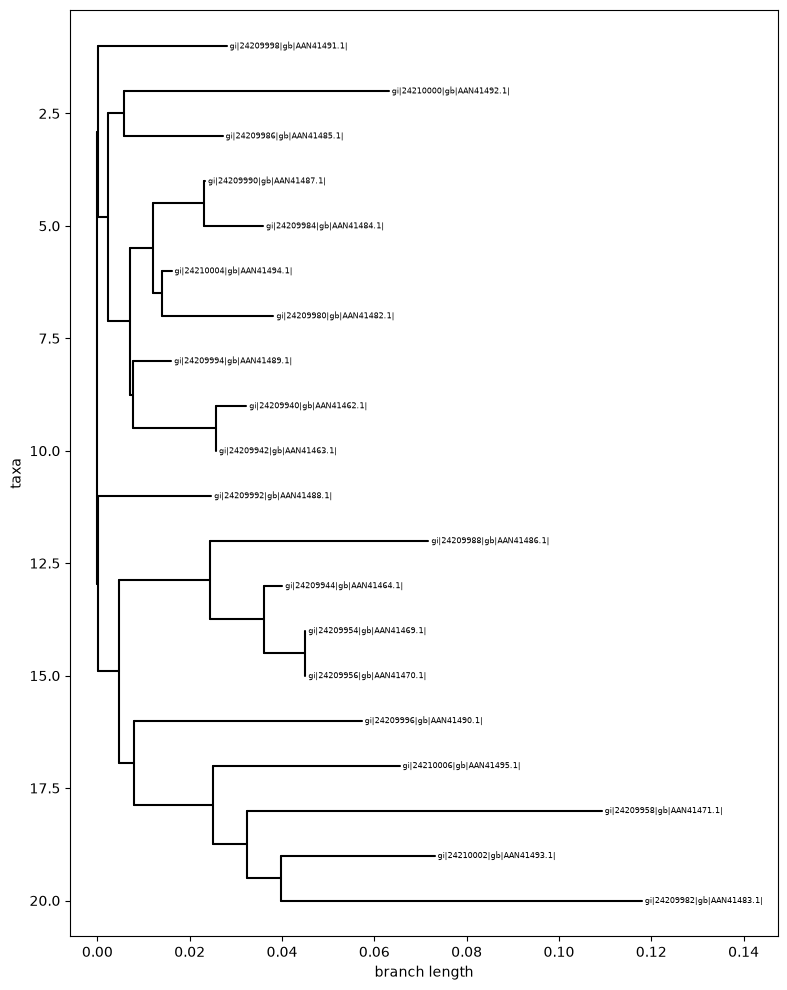

In [11]:
if __name__ == "__main__":
    # Read HIV RT sequences
    sequences = read_fasta("lafayette_SARS_RT.fasta")
    
    # Build distance matrix using Smith-Waterman
    dist_matrix, seq_ids = build_distance_matrix(sequences)
    
    # Generate unrooted tree using Neighbor-Joining
    tree = neighbor_joining(dist_matrix, seq_ids)
    
    # Plot tree
    plot_tree(tree)